In [2]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

In [4]:
# ==========================================
# BRAIN MRI DATASET PATHS
# ==========================================

train_dir = "processed_data/brain_mri/train"
validation_dir = "processed_data/brain_mri/validation"
test_dir = "processed_data/brain_mri/test"

print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(validation_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


In [5]:
# ==========================================
# LOAD BRAIN MRI DATASET
# ==========================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 279 files belonging to 2 classes.
Found 60 files belonging to 2 classes.
Found 61 files belonging to 2 classes.


In [6]:
print("Classes:", train_ds.class_names)

Classes: ['Normal', 'Tumor']


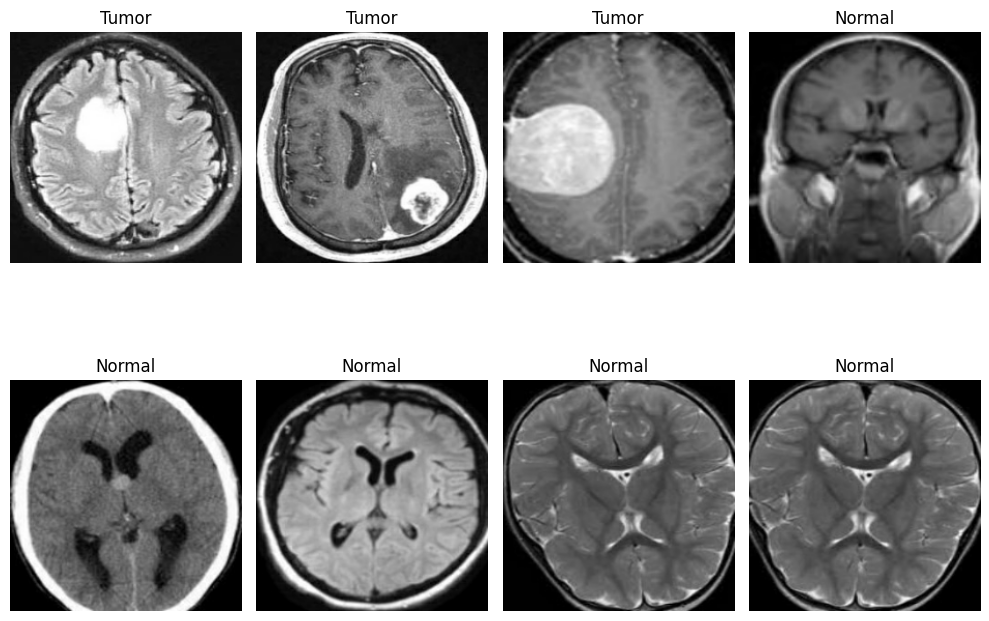

In [7]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):

    for i in range(8):

        plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(train_ds.class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# ==========================================
# CREATE EFFICIENTNETB0 MODEL
# ==========================================

base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained model
base_model.trainable = False

print("Base model loaded successfully!")
print("Total layers:", len(base_model.layers))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Base model loaded successfully!
Total layers: 238


In [9]:
# ==========================================
# ADD OUR CLASSIFICATION LAYER
# ==========================================

inputs = keras.Input(shape=(224, 224, 3))

# Pass image through EfficientNet
x = base_model(inputs, training=False)

# Convert feature maps into a single vector
x = layers.GlobalAveragePooling2D()(x)

# Helps reduce overfitting
x = layers.Dropout(0.3)(x)

# Binary classification
outputs = layers.Dense(1, activation="sigmoid")(x)

# Create final model
model = keras.Model(inputs, outputs)

print("Model created successfully!")

Model created successfully!


In [10]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [11]:
# ==========================================
# COMPILE MODEL
# ==========================================

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
# ==========================================
# DATA AUGMENTATION
# ==========================================

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
], name="data_augmentation")

print("Data augmentation created!")

Data augmentation created!


In [13]:
# ==========================================
# ADD AUGMENTATION TO MODEL
# ==========================================

inputs = keras.Input(shape=(224, 224, 3))

# Augmentation
x = data_augmentation(inputs)

# EfficientNet
x = base_model(x, training=False)

# Convert features into one vector
x = layers.GlobalAveragePooling2D()(x)

# Dropout
x = layers.Dropout(0.3)(x)

# Output
outputs = layers.Dense(1, activation="sigmoid")(x)

# Final model
model = keras.Model(inputs, outputs)

print("Updated model created!")

Updated model created!


In [14]:
# ==========================================
# COMPILE UPDATED MODEL
# ==========================================

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Model compiled!")

Model compiled!


In [15]:
# ==========================================
# TRAINING CALLBACKS
# ==========================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.000001
)

print("Callbacks created!")

Callbacks created!


In [16]:
# ==========================================
# TRAIN BRAIN MRI MODEL
# ==========================================

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/20


c:\Users\srava\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


18/18 ━━━━━━━━━━━━━━━━━━━━ 21s 588ms/step - accuracy: 0.4946 - loss: 0.7447 - precision: 0.6136 - recall: 0.3354 - val_accuracy: 0.5000 - val_loss: 0.6542 - val_precision: 0.6000 - val_recall: 0.3529 - learning_rate: 1.0000e-04
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 437ms/step - accuracy: 0.5556 - loss: 0.7094 - precision: 0.6796 - recall: 0.4348 - val_accuracy: 0.6333 - val_loss: 0.6290 - val_precision: 0.7000 - val_recall: 0.6176 - learning_rate: 1.0000e-04
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 429ms/step - accuracy: 0.5950 - loss: 0.6768 - precision: 0.6846 - recall: 0.5528 - val_accuracy: 0.7000 - val_loss: 0.6130 - val_precision: 0.7105 - val_recall: 0.7941 - learning_rate: 1.0000e-04
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 433ms/step - accuracy: 0.6487 - loss: 0.6460 - precision: 0.7032 - recall: 0.6770 - val_accuracy: 0.7333 - val_loss: 0.6010 - val_precision: 0.7143 - val_recall: 0.8824 - learning_rate: 1.0000e-04
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 8s 424ms/step - accu

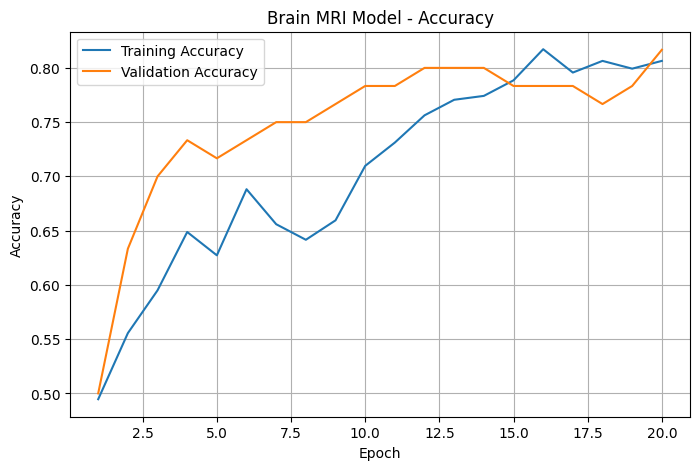

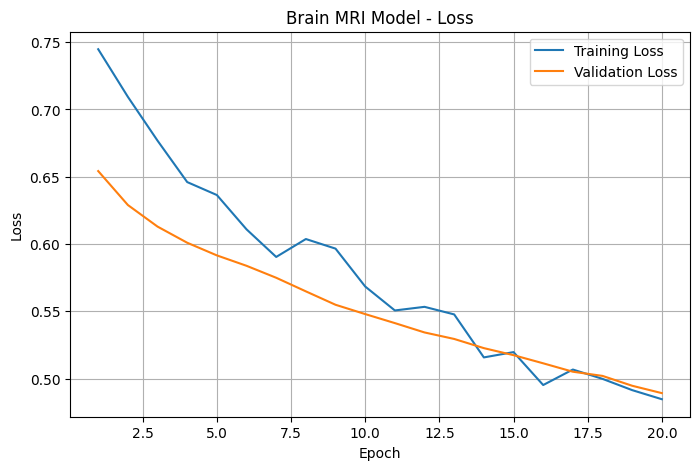

In [17]:
# ==========================================
# PLOT TRAINING RESULTS
# ==========================================

history_dict = history.history

train_accuracy = history_dict["accuracy"]
validation_accuracy = history_dict["val_accuracy"]

train_loss = history_dict["loss"]
validation_loss = history_dict["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    validation_accuracy,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Brain MRI Model - Accuracy")
plt.legend()
plt.grid()

plt.show()


# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    validation_loss,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Brain MRI Model - Loss")
plt.legend()
plt.grid()

plt.show()

In [18]:
# ==========================================
# EVALUATE BRAIN MRI MODEL ON TEST DATA
# ==========================================

test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\nTest Results:")
print("Loss      :", test_results[0])
print("Accuracy  :", test_results[1])
print("Precision :", test_results[2])
print("Recall    :", test_results[3])

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 381ms/step - accuracy: 0.8361 - loss: 0.4787 - precision: 0.7907 - recall: 0.9714     

Test Results:
Loss      : 0.47865429520606995
Accuracy  : 0.8360655903816223
Precision : 0.7906976938247681
Recall    : 0.9714285731315613


In [19]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predictions = (predictions >= 0.5).astype(int).flatten()

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

confusion_matrix = tf.math.confusion_matrix(
    y_true,
    y_pred,
    num_classes=2
).numpy()

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[17  9]
 [ 1 34]]


In [20]:
# ==========================================
# F1 SCORE
# ==========================================

TN = confusion_matrix[0][0]
FP = confusion_matrix[0][1]
FN = confusion_matrix[1][0]
TP = confusion_matrix[1][1]

precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0
    else 0
)

print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1_score, 4))

Precision : 0.7907
Recall    : 0.9714
F1 Score  : 0.8718


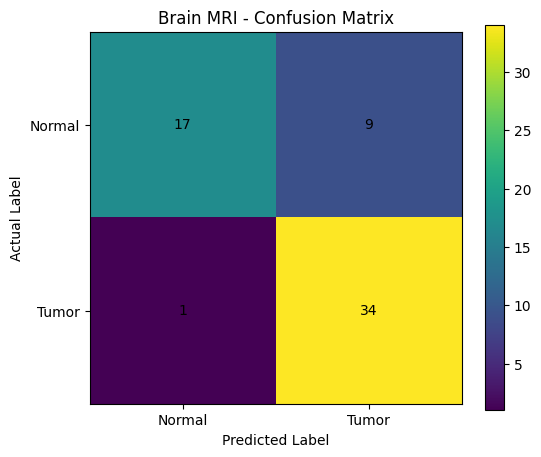

In [21]:
# ==========================================
# DISPLAY CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(confusion_matrix)

plt.title("Brain MRI - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Normal", "Tumor"])
plt.yticks([0, 1], ["Normal", "Tumor"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [22]:
# ==========================================
# TEST THE BRAIN MRI MODEL
# ==========================================

test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== TEST RESULTS ==========")
print("Test Loss      :", round(test_results[0], 4))
print("Test Accuracy  :", round(test_results[1], 4))
print("Test Precision :", round(test_results[2], 4))
print("Test Recall    :", round(test_results[3], 4))

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 397ms/step - accuracy: 0.8361 - loss: 0.4787 - precision: 0.7907 - recall: 0.9714     

========== TEST RESULTS ==========
Test Loss      : 0.4787
Test Accuracy  : 0.8361
Test Precision : 0.7907
Test Recall    : 0.9714


In [23]:
# ==========================================
# GET TEST PREDICTIONS
# ==========================================

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_labels = (
        predictions >= 0.5
    ).astype(int).flatten()

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels    :", len(y_true))
print("Predicted labels :", len(y_pred))

Actual labels    : 61
Predicted labels : 61


In [24]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

confusion_matrix = tf.math.confusion_matrix(
    y_true,
    y_pred,
    num_classes=2
).numpy()

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[17  9]
 [ 1 34]]


In [25]:
# ==========================================
# PRECISION, RECALL AND F1 SCORE
# ==========================================

TN = confusion_matrix[0][0]
FP = confusion_matrix[0][1]
FN = confusion_matrix[1][0]
TP = confusion_matrix[1][1]

precision = TP / (TP + FP) if (TP + FP) != 0 else 0
recall = TP / (TP + FN) if (TP + FN) != 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print("========== FINAL METRICS ==========")
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1 Score  :", round(f1, 4))

========== FINAL METRICS ==========
Precision : 0.7907
Recall    : 0.9714
F1 Score  : 0.8718


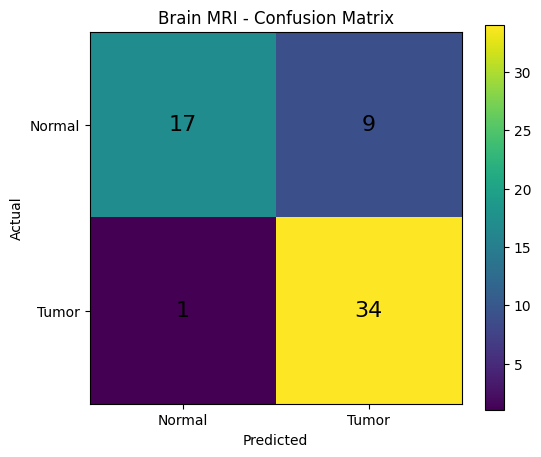

In [26]:
# ==========================================
# DISPLAY CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(6, 5))

plt.imshow(confusion_matrix)

plt.title("Brain MRI - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Normal", "Tumor"])
plt.yticks([0, 1], ["Normal", "Tumor"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            confusion_matrix[i][j],
            ha="center",
            va="center",
            fontsize=16
        )

plt.colorbar()
plt.show()

In [27]:
# ==========================================
# SAVE FIRST BRAIN MRI MODEL
# ==========================================

model.save("brain_mri_efficientnet_initial.keras")

print("Brain MRI model saved successfully!")

Brain MRI model saved successfully!


In [28]:
# ==========================================
# FINE-TUNING EFFICIENTNETB0
# ==========================================

# First keep the whole model frozen
base_model.trainable = True

# Freeze most of EfficientNet
for layer in base_model.layers[:-20]:
    layer.trainable = False

print("Total EfficientNet layers:", len(base_model.layers))

trainable_layers = 0

for layer in base_model.layers:
    if layer.trainable:
        trainable_layers += 1

print("Trainable EfficientNet layers:", trainable_layers)

Total EfficientNet layers: 238
Trainable EfficientNet layers: 20


In [29]:
# ==========================================
# RECOMPILE FOR FINE-TUNING
# ==========================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

print("Model recompiled for fine-tuning!")

Model recompiled for fine-tuning!


In [30]:
# ==========================================
# FINE-TUNE THE MODEL
# ==========================================

fine_tune_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10


c:\Users\srava\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


18/18 ━━━━━━━━━━━━━━━━━━━━ 24s 618ms/step - accuracy: 0.6738 - loss: 0.6257 - precision: 0.8070 - recall: 0.5714 - val_accuracy: 0.8000 - val_loss: 0.4841 - val_precision: 0.7500 - val_recall: 0.9706 - learning_rate: 1.0000e-05
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 534ms/step - accuracy: 0.7061 - loss: 0.5904 - precision: 0.8496 - recall: 0.5963 - val_accuracy: 0.8000 - val_loss: 0.4818 - val_precision: 0.7500 - val_recall: 0.9706 - learning_rate: 1.0000e-05
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 527ms/step - accuracy: 0.8100 - loss: 0.5467 - precision: 0.9030 - recall: 0.7516 - val_accuracy: 0.8167 - val_loss: 0.4791 - val_precision: 0.7805 - val_recall: 0.9412 - learning_rate: 1.0000e-05
Epoch 4/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 512ms/step - accuracy: 0.7670 - loss: 0.5516 - precision: 0.8529 - recall: 0.7205 - val_accuracy: 0.7833 - val_loss: 0.4776 - val_precision: 0.7692 - val_recall: 0.8824 - learning_rate: 1.0000e-05
Epoch 5/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 510ms/step - ac

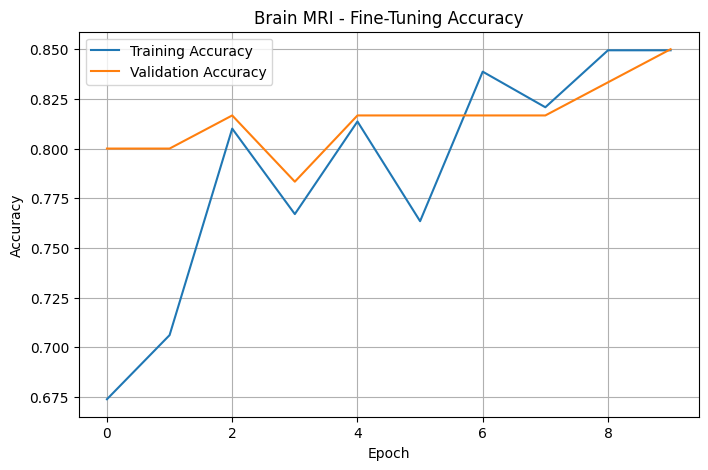

In [31]:
# ==========================================
# PLOT FINE-TUNING RESULTS
# ==========================================

history_dict = fine_tune_history.history

plt.figure(figsize=(8, 5))

plt.plot(
    history_dict["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_dict["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Brain MRI - Fine-Tuning Accuracy")
plt.legend()
plt.grid()

plt.show()

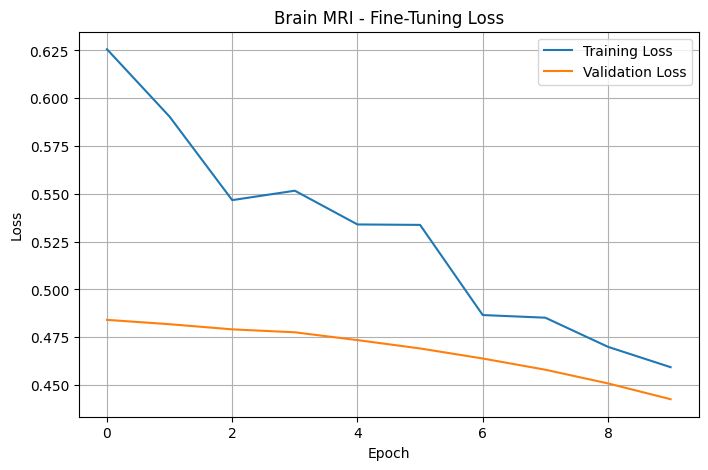

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_dict["loss"],
    label="Training Loss"
)

plt.plot(
    history_dict["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Brain MRI - Fine-Tuning Loss")
plt.legend()
plt.grid()

plt.show()

In [33]:
# ==========================================
# FINAL TEST EVALUATION
# ==========================================

final_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== FINAL TEST RESULTS ==========")
print("Test Loss      :", round(final_results[0], 4))
print("Test Accuracy  :", round(final_results[1], 4))
print("Test Precision :", round(final_results[2], 4))
print("Test Recall    :", round(final_results[3], 4))

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 375ms/step - accuracy: 0.8197 - loss: 0.4509 - precision: 0.8333 - recall: 0.8571     

========== FINAL TEST RESULTS ==========
Test Loss      : 0.4509
Test Accuracy  : 0.8197
Test Precision : 0.8333
Test Recall    : 0.8571


In [34]:
# ==========================================
# FINAL CONFUSION MATRIX
# ==========================================

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_labels = (
        predictions >= 0.5
    ).astype(int).flatten()

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

final_cm = tf.math.confusion_matrix(
    y_true,
    y_pred,
    num_classes=2
).numpy()

print("Final Confusion Matrix:")
print(final_cm)

Final Confusion Matrix:
[[20  6]
 [ 5 30]]


In [35]:
# ==========================================
# SAVE FINAL BRAIN MRI MODEL
# ==========================================

model.save("brain_mri_efficientnet_final.keras")

print("Final Brain MRI model saved!")

Final Brain MRI model saved!
